In [1]:
import pandas as pd

url = "GSAF5.xls"
df = pd.read_excel(url, engine="xlrd")

df

,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,Species,Source,pdf,href formula,href,Case Number,Case Number.1,original order,Unnamed: 21,Unnamed: 22
0,18th September,2026.0,Unprovoked,Australia,Western Australia,Sorrento Beach Perth,Swimming,Greg O'Neil,M,63,...,Great White Shark 6m (20ft),Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,16th September,2026.0,Unprovoked,Canada,Quebec,Off the coast of Perce Le Bilbo dive site,Diving,Unknown Male,M,?,...,Great White Shark,Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,14th September,2026.0,Unprovoked,Bahamas,Bimini,Bimini Island,Swimming,Unknown Austrian Tourist,F,37,...,Unknown,Kevin McMurray Trackingsharks.com: Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,13th September,2026.0,Unprovoked,Australia,Western Australia,Geraldton,Surfing,Mel Ismail,M,50's,...,Unknown,Simon De Marchi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7th September,2026.0,Unprovoked,USA,Hawaii,Honolulu,Surfing,Wants to remain anonymous,M,24,...,Tiger Shark suspected,Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7120,Before 1903,0.0,Unprovoked,AUSTRALIA,Western Australia,Roebuck Bay,Diving,male,M,NaN,...,NaN,"H. Taunton; N. Bartlett, p. 234",ND-0005-RoebuckBay.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0005,ND.0005,6.0,NaN,NaN
7121,Before 1903,0.0,Unprovoked,AUSTRALIA,Western Australia,NaN,Pearl diving,Ahmun,M,NaN,...,NaN,"H. Taunton; N. Bartlett, pp. 233-234",ND-0004-Ahmun.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0004,ND.0004,5.0,NaN,NaN
7122,1900-1905,0.0,Unprovoked,USA,North Carolina,Ocracoke Inlet,Swimming,Coast Guard personnel,M,NaN,...,NaN,"F. Schwartz, p.23; C. Creswell, GSAF",ND-0003-Ocracoke_1900-1905.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0003,ND.0003,4.0,NaN,NaN
7123,1883-1889,0.0,Unprovoked,PANAMA,NaN,"Panama Bay 8ºN, 79ºW",NaN,Jules Patterson,M,NaN,...,NaN,"The Sun, 10/20/1938",ND-0002-JulesPatterson.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0002,ND.0002,3.0,NaN,NaN


In [2]:
df.shape
df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7125 entries, 0 to 7124
Data columns (total 23 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            7125 non-null   object 
 1   Year            7123 non-null   float64
 2   Type            7107 non-null   str    
 3   Country         7075 non-null   str    
 4   State           6638 non-null   str    
 5   Location        6558 non-null   str    
 6   Activity        6542 non-null   str    
 7   Name            6907 non-null   str    
 8   Sex             6547 non-null   str    
 9   Age             4131 non-null   object 
 10  Injury          7089 non-null   str    
 11  Fatal Y/N       6564 non-null   object 
 12  Time            3598 non-null   object 
 13  Species         3994 non-null   str    
 14  Source          7105 non-null   object 
 15  pdf             6799 non-null   object 
 16  href formula    6794 non-null   str    
 17  href            6796 non-null   str    
 18 

In [3]:
#Lowercase, snake_case names; simplify the fatal column

df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df = df.rename(columns={"fatal_y/n": "fatal"})

columns_to_keep = ["type", "year", "country", "state", "activity",
                   "date", "fatal"]

df_clean = df[columns_to_keep].copy()

In [4]:
#Column names after renaming

print(df_clean.columns.tolist())
display(df_clean.head())

['type', 'year', 'country', 'state', 'activity', 'date', 'fatal']


,type,year,country,state,activity,date,fatal
0,Unprovoked,2026.0,Australia,Western Australia,Swimming,18th September,Y
1,Unprovoked,2026.0,Canada,Quebec,Diving,16th September,N
2,Unprovoked,2026.0,Bahamas,Bimini,Swimming,14th September,N
3,Unprovoked,2026.0,Australia,Western Australia,Surfing,13th September,N
4,Unprovoked,2026.0,USA,Hawaii,Surfing,7th September,N


In [5]:
#### Start of "type" cleaning ####

#Standardise formatting
df_clean["type"] = (
    df_clean["type"]
    .str.strip()
    .str.title()
)
df_clean["type"].unique()

#Group all uncertain categories into one
type_map = {
    "Questionable": "Unconfirmed",
    "?": "Unconfirmed",
    "Unverified": "Unconfirmed",
    "Invalid": "Unconfirmed",
    "Under Investigation": "Unconfirmed"
}

df_clean["type_clean"] = df_clean["type"].replace(type_map)

#missing type = unconfirmed
df_clean["type_clean"] = df_clean["type_clean"].fillna("Unconfirmed")

df_clean["type_clean"].value_counts()

#df.type.unique()

# print(df_clean.shape)
# display(df_clean["type_clean"].value_counts())
# print("Year range:", df_clean["year"].min(), "-", df_clean["year"].max())

type_clean
Unprovoked      5271
Provoked         649
Unconfirmed      601
Watercraft       355
Sea Disaster     242
Boat               7
Name: count, dtype: int64

In [6]:
df_clean.year.info()
df_clean.year.nunique()
df_clean.year.unique()

<class 'pandas.Series'>
RangeIndex: 7125 entries, 0 to 7124
Series name: year
Non-Null Count  Dtype  
--------------  -----  
7123 non-null   float64
dtypes: float64(1)
memory usage: 55.8 KB


array([2026., 2025., 2024., 2023., 2022., 2021., 2020., 2019., 2018.,
       2017.,   nan, 2016., 2015., 2014., 2013., 2012., 2011., 2010.,
       2009., 2008., 2007., 2006., 2005., 2004., 2003., 2002., 2001.,
       2000., 1999., 1998., 1997., 1996., 1995., 1984., 1994., 1993.,
       1992., 1991., 1990., 1989., 1969., 1988., 1987., 1986., 1985.,
       1983., 1982., 1981., 1980., 1979., 1978., 1977., 1976., 1975.,
       1974., 1973., 1972., 1971., 1970., 1968., 1967., 1966., 1965.,
       1964., 1963., 1962., 1961., 1960., 1959., 1958., 1957., 1956.,
       1955., 1954., 1953., 1952., 1951., 1950., 1949., 1948., 1848.,
       1947., 1946., 1945., 1944., 1943., 1942., 1941., 1940., 1939.,
       1938., 1937., 1936., 1935., 1934., 1933., 1932., 1931., 1930.,
       1929., 1928., 1927., 1926., 1925., 1924., 1923., 1922., 1921.,
       1920., 1919., 1918., 1917., 1916., 1915., 1914., 1913., 1912.,
       1911., 1910., 1909., 1908., 1907., 1906., 1905., 1904., 1903.,
       1902., 1901.,

In [7]:
#### Start of "year" cleaning ####

#Before cleaning: type and missing values
print("Type before cleaning:", df_clean["year"].dtype)
print("Missing years:", df_clean["year"].isna().sum())
print("Invalid years (below 1500):", (df_clean["year"] < 1500).sum())

#Treat impossible years as missing
df_clean.loc[df_clean["year"] < 1500, "year"] = pd.NA

#Convert to whole numbers allowing missing values
df_clean["year"] = df_clean["year"].astype("Int64")

#After cleaning
print("Type after cleaning:", df_clean["year"].dtype)
print("Range:", df_clean["year"].min(), "-", df_clean["year"].max())

Type before cleaning: float64
Missing years: 2
Invalid years (below 1500): 132
Type after cleaning: Int64
Range: 1500 - 2026


In [8]:
print("Year range:", df_clean["year"].min(), "-", df_clean["year"].max())
display(df_clean["type_clean"].value_counts())

Year range: 1500 - 2026


type_clean
Unprovoked      5271
Provoked         649
Unconfirmed      601
Watercraft       355
Sea Disaster     242
Boat               7
Name: count, dtype: int64

In [9]:
#### Start of "country" cleaning ####

#Clean basic formatting
df_clean["country"] = df_clean["country"].str.strip().str.title()

#Before corrections: how many countries
print("Countries before corrections:", df_clean["country"].nunique(dropna=False))

#Standardise country names
country_corrections = {
    "Usa": "USA", "U.S.A.": "USA", "Us": "USA",
    "United States": "USA", "United States Of America": "USA",
    "Uk": "UK", "U.K.": "UK", "United Kingdom": "UK", "Great Britain": "UK",
    "Uae": "UAE",
    "Bahrein": "Bahrain",
    "Ceylon (Sri Lanka)": "Sri Lanka", "Ceylon": "Sri Lanka",
    "Burma": "Myanmar",
    "Persian Gulf": "Unknown", "Red Sea?": "Unknown", "Asia?": "Unknown"   #regions, not countries
}
df_clean["country"] = df_clean["country"].replace(country_corrections)

#missing country = unknown
df_clean["country"] = df_clean["country"].fillna("Unknown")

Countries before corrections: 215


In [10]:
#Countries and number of incidents, as a table
country_counts = df_clean["country"].value_counts().reset_index()
country_counts.columns = ["country", "incidents"]

display(country_counts.head(20))

,country,incidents
0,USA,2597
1,Australia,1538
2,South Africa,599
3,Bahamas,146
4,New Zealand,146
5,Papua New Guinea,136
6,Brazil,125
7,Mexico,107
8,Italy,72
9,Fiji,71


In [11]:
#### Start of "state" cleaning ####

#Clean basic formatting, so "Florida" and "FLORIDA " count as one
df_clean["state"] = df_clean["state"].str.strip().str.title()
df_clean["state"] = df_clean["state"].fillna("Unknown")   #missing state = unknown

#How many states and how many unknown
print("Number of states:", df_clean["state"].nunique())
unknown_states = (df_clean["state"] == "Unknown").sum()
print(f"Unknown state: {unknown_states} rows ({unknown_states / len(df_clean) * 100:.1f}%)")

#The 10 most common states, shown with their country (excluding unknown)
known_states = df_clean[df_clean["state"] != "Unknown"]
top_states = known_states.groupby(["country", "state"]).size().sort_values(ascending=False).head(10)

display(top_states)

#Keep only rows with those states
top_state_names = top_states.index.get_level_values("state")
df_clean_top_states = df_clean[df_clean["state"].isin(top_state_names)]

Number of states: 926
Unknown state: 487 rows (6.8%)


country       state                
USA           Florida                  1200
Australia     New South Wales           523
              Queensland                357
USA           Hawaii                    348
              California                328
Australia     Western Australia         248
South Africa  Kwazulu-Natal             219
              Western Cape Province     197
USA           South Carolina            176
South Africa  Eastern Cape Province     168
dtype: int64

In [12]:
#Countries and number of incidents

state_counts = df_clean["state"].value_counts().reset_index()
state_counts.columns = ["state", "incidents"]

display(state_counts.head(20))

,state,incidents
0,Florida,1200
1,New South Wales,523
2,Unknown,487
3,Queensland,357
4,Hawaii,348
5,California,328
6,Western Australia,248
7,Kwazulu-Natal,219
8,Western Cape Province,197
9,South Carolina,177


In [13]:
#### Start of "activity" filtering ####

# #Standardise formatting and fill missing values
# df_clean["activity"] = df_clean["activity"].str.strip().str.title()
# df_clean["activity"] = df_clean["activity"].fillna("Unknown")

# def clean_activity(activity):
#     """Group an activity into a category based on keywords."""
#     if activity == "Unknown":      #keep missing values as their own group
#         return "unknown"
#     for value in ["Swim", "Dive" "Diving", "Surf", "Fish", "Wading",
#                 "Rescue", "Snorkeling", "Hydrofoiling", "Bathing", "Paddle", "Sailing", "Floating", "Kayaking"]:
#         if value.lower() in activity.lower():
#             return value.lower()   #first keyword found wins
#     return "other"                 #only reached if no keyword matched

# #Save the grouped activity in a new column
# df_clean["activity_clean"] = df_clean["activity"].apply(clean_activity)

# df_clean["activity_clean"].value_counts()

In [14]:
#### Start of "activity" cleaning ####

def clean_activity(activity):

    # Deal with missing activity
    if pd.isna(activity):
        return "Unknown"

    # Clean basic formatting
    activity = str(activity).strip().lower()

    # Put each activity into a category
    if "surf" in activity:
        return "Surfing"

    elif "swim" in activity:
        return "Swimming"

    elif "spearfish" in activity:
        return "Spearfishing"

    elif "fish" in activity:
        return "Fishing"

    elif "wading" in activity or "wade" in activity:
        return "Wading"

    elif "bath" in activity:
        return "Bathing"

    elif "diving" in activity or "diver" in activity or "dive" in activity:
        return "Diving"

    elif "snorkel" in activity:
        return "Snorkeling"

    elif "stand" in activity:
        return "Standing"
    else:
        return "Other"

clean_activity("activity")

'Other'

In [15]:
df_clean["activity_clean"] = (df_clean["activity"].apply(clean_activity))
df_clean["activity_clean"]

0       Swimming
1         Diving
2       Swimming
3        Surfing
4        Surfing
          ...   
7120      Diving
7121      Diving
7122    Swimming
7123     Unknown
7124    Swimming
Name: activity_clean, Length: 7125, dtype: str

In [16]:
activity_counts = df_clean["activity_clean"].value_counts()
print(activity_counts)

activity_clean
Surfing         1471
Swimming        1278
Other           1220
Fishing          834
Unknown          583
Diving           572
Spearfishing     489
Wading           191
Bathing          191
Standing         154
Snorkeling       142
Name: count, dtype: int64


In [17]:
#df_clean.loc[df_clean["activity_clean"] == "other", "activity"].value_counts().head(20)

In [18]:
#### Start of "date" cleaning ####

#Map month abbreviations to numbers
month_map = {"jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
             "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12}

#Find the month name in the text and convert it to a number ("18th September" -> 9)
df_clean["month"] = (
    df_clean["date"]
    .astype(str)      #convert every value to text, so the regex works on all rows
    .str.lower()      #lowercase everything, so "Sep", "SEP" and "sep" all match
    .str.extract(r"(jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)")[0]  #find the month abbreviation
    .map(month_map)   #convert the abbreviation to a number
)

#Dates stored as real dates (e.g., 2025-06-11) have no month name: read them as dates
df_clean["month"] = df_clean["month"].fillna(
    pd.to_datetime(df_clean["date"], format="mixed", errors="coerce").dt.month)

#Whole numbers 1-12, allowing missing values
df_clean["month"] = df_clean["month"].astype("Int64")

#Check: incidents per month and rows without a month
df_clean["month"].value_counts().sort_index()
df_clean["month"].isna().sum()

np.int64(233)

In [19]:
#Incidents per month, as a table in calendar order
month_counts = df_clean["month"].value_counts().sort_index().reset_index()
month_counts.columns = ["month", "incidents"]
display(month_counts)

print("Rows without a month:", df_clean["month"].isna().sum())

,month,incidents
0,1,878
1,2,428
2,3,468
3,4,505
4,5,468
5,6,567
6,7,803
7,8,681
8,9,621
9,10,507


Rows without a month: 233


In [20]:
#### Start of "fatal" cleaning ####

#Before cleaning: how many categories and which ones
print("Categories before cleaning:", df_clean["fatal"].nunique(dropna=False))
display(df_clean["fatal"].value_counts(dropna=False))

#Standardise formatting
df_clean["fatal_clean"] = df_clean["fatal"].astype(str).str.strip().str.upper()

#Fix known variants
fatal_corrections = {"Y X 2": "Y", "NQ": "N"}
df_clean["fatal_clean"] = df_clean["fatal_clean"].replace(fatal_corrections)

#Anything that isn't Y or N becomes Unknown
df_clean.loc[~df_clean["fatal_clean"].isin(["Y", "N"]), "fatal_clean"] = "Unknown"

#After cleaning
print("Categories after cleaning:", df_clean["fatal_clean"].nunique())
display(df_clean["fatal_clean"].value_counts())

Categories before cleaning: 13


fatal
N          4977
Y          1495
NaN         561
UNKNOWN      71
 N            7
F             5
M             3
n             1
Nq            1
2017          1
Y x 2         1
N             1
y             1
Name: count, dtype: int64

Categories after cleaning: 3


fatal_clean
N          4987
Y          1497
Unknown     641
Name: count, dtype: int64

In [21]:
#After cleaning: how many categories
print("Categories after cleaning:", df_clean["fatal_clean"].nunique())

#Fatal vs non-fatal incidents, as a table with percentages
fatal_counts = df_clean["fatal_clean"].value_counts().reset_index()
fatal_counts.columns = ["fatal", "incidents"]
fatal_counts["percentage"] = (fatal_counts["incidents"] / fatal_counts["incidents"].sum() * 100).round(1)

display(fatal_counts)

Categories after cleaning: 3


,fatal,incidents,percentage
0,N,4987,70.0
1,Y,1497,21.0
2,Unknown,641,9.0


In [22]:
# display(df_clean_top_countries)
# display(df_clean_top_states)
# #df_clean_top_countries = get_top_values(df_clean, "country").head(20)

In [23]:
# import re

# def identify_period(date):
#     if re.match(r"\d{4}-\d{4}", date):
#         return "Period"
#     else:
#         return date

# df_clean["date"].apply(identify_period)
# df_clean[ df_clean["date"] != "Period" ]

In [24]:
#### Apply the project scope ####

In [25]:
def clean_data(file_path):
    """Run all cleaning steps in order and return the cleaned dataset."""
    df = load_data(file_path)
    df = clean_column_names(df)
    df = select_columns(df)
    df = clean_type(df)
    df = clean_year(df)
    df = remove_duplicates(df)
    df = clean_country(df)
    df = clean_state(df)
    df = clean_activity(df)
    df = add_month(df)
    df = clean_fatal(df)
    return df

In [26]:
#### Apply the project scope to "type" ####
#beach-related incidents only
df_clean = df_clean[df_clean["type"].isin(["Unprovoked", "Provoked"])]

#recent period only
df_clean = df_clean[df_clean["year"] >= 2000]

#2026.0 -> 2026
df_clean["year"] = df_clean["year"].astype(int)
df_clean.shape

(2506, 11)

In [27]:
#Calculate percentages
activity_percentage = (
    df_clean["activity_clean"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
)

print(activity_percentage)

activity_clean
Surfing         35.7
Swimming        17.4
Other           11.4
Fishing          7.6
Spearfishing     7.2
Diving           5.7
Snorkeling       4.8
Wading           4.0
Unknown          3.5
Standing         2.6
Bathing          0.2
Name: proportion, dtype: float64


In [28]:
#Combine counts and percentages
activity_summary = pd.DataFrame({
    "number_of_incidents": activity_counts,
    "percentage": activity_percentage
})

print(activity_summary)

                number_of_incidents  percentage
activity_clean                                 
Bathing                         191         0.2
Diving                          572         5.7
Fishing                         834         7.6
Other                          1220        11.4
Snorkeling                      142         4.8
Spearfishing                    489         7.2
Standing                        154         2.6
Surfing                        1471        35.7
Swimming                       1278        17.4
Unknown                         583         3.5
Wading                          191         4.0


In [29]:
#### Apply the project scope to "countries" ####
#After corrections: how many countries
print("Countries after corrections:", df_clean["country"].nunique())

#How many incidents have no known country
unknown_count = (df_clean["country"] == "Unknown").sum()
#print(f"Unknown country: {unknown_count} rows ({unknown_count / len(df_clean) * 100:.1f}%)")

#The 10 most common countries (excluding unknown)
top_countries = df_clean.loc[df_clean["country"] != "Unknown", "country"].value_counts().head(10).index

#Keep only rows with those countries
df_clean_top_countries = df_clean[df_clean["country"].isin(top_countries)]

display(df_clean_top_countries["country"].value_counts())

Countries after corrections: 98


country
USA                 1234
Australia            503
South Africa         129
Bahamas               83
Brazil                61
New Zealand           44
New Caledonia         38
Mexico                34
French Polynesia      31
Egypt                 30
Name: count, dtype: int64

In [30]:
#### Apply the time scope on the "year": 2000 onwards ####
rows_before = len(df_clean)
df_clean = df_clean[df_clean["year"] >= 2000]

display(df_clean["year"].value_counts().sort_index())

year
2000     82
2001     76
2002     83
2003     83
2004     76
2005     84
2006     86
2007     97
2008    100
2009    101
2010     94
2011    109
2012    101
2013    113
2014    104
2015    117
2016    117
2017    116
2018    105
2019    101
2020     91
2021    105
2022     93
2023     95
2024     51
2025     66
2026     60
Name: count, dtype: int64

In [31]:
# #### Apply the time scope on activity ####
# # the 10 most common activities
# df_activity = df_clean[~df_clean["activity_clean"].isin(["unknown", "other"])]

In [32]:
import matplotlib.pyplot as plt

def plot_bar(counts, title, xlabel, ylabel, file_name, highlight=None):
    """Plot a bar chart from value counts and save it as a PNG for the slides."""
    colors = ["#E4572E" if label in (highlight or []) else "#A0A4A8" for label in counts.index]

    fig, ax = plt.subplots(figsize=(10, 5.6))   #16:9 shape, fits a slide
    ax.bar(counts.index.astype(str), counts.values, color=colors)

    ax.set_title(title, fontsize=16, fontweight="bold", loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)   #remove unnecessary borders
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.savefig(file_name, dpi=200, bbox_inches="tight")   #high resolution for the slides
    plt.show()

In [33]:
fatal_counts = df_clean["fatal_clean"].value_counts().reset_index()
fatal_counts.columns = ["fatal", "incidents"]
fatal_counts["percentage"] = (fatal_counts["incidents"] / fatal_counts["incidents"].sum() * 100).round(1)

display(fatal_counts)

,fatal,incidents,percentage
0,N,2231,89.0
1,Y,253,10.1
2,Unknown,22,0.9


In [34]:
# #H1: incidents by country
# top_countries = df_clean["country"].value_counts().head(10)
# plot_bar(top_countries, "USA and Australia lead shark incidents since 2000",
#          "Country", "Incidents", "h1_countries.png", highlight=["USA", "Australia"])

# #H2: incidents by activity
# top_activities = df_clean["activity_clean"].value_counts().head(8)
# plot_bar(top_activities, "Surfing is the activity with the most incidents",
#          "Activity", "Incidents", "h2_activities.png", highlight=["Surfing"])

In [35]:
#### Apply the project scope ####
rows_before = len(df_clean)

#beach-related incidents only
df_clean = df_clean[df_clean["type"].isin(["Unprovoked", "Provoked"])]

#recent period only (2000-2026)
df_clean = df_clean[df_clean["year"] >= 2000]

#2026.0 -> 2026
df_clean["year"] = df_clean["year"].astype(int)

print(f"Rows kept: {len(df_clean)} of {rows_before}")

Rows kept: 2506 of 2506


In [36]:
#### Scope H1 - Geographic concentration ####

In [37]:
#### H1: Country analysis ####

#Country with the most incidents
country_summary = (
    df_clean.groupby("country")
    .agg(incidents=("country", "size"))
    .sort_values("incidents", ascending=False)
    .reset_index()
)
country_summary["percentage"] = (country_summary["incidents"] / country_summary["incidents"].sum() * 100).round(1)

top_country = country_summary.iloc[0]
print(f"Country with the most incidents: {top_country['country']} "
      f"({top_country['incidents']} incidents, {top_country['percentage']}% of all countries)")

country_df = df_clean[df_clean["country"] == top_country["country"]]

#Year with the most incidents ever recorded in that country
country_years = country_df.groupby("year").agg(incidents=("year", "size")).reset_index()
peak_year = country_years.loc[country_years["incidents"].idxmax()]
print(f"Peak year in {top_country['country']}: {peak_year['year']} ({peak_year['incidents']} incidents)")

#Growth of incidents between 2000 and 2025
inc_2000 = country_years.loc[country_years["year"] == 2000, "incidents"].iloc[0]
inc_2025 = country_years.loc[country_years["year"] == 2025, "incidents"].iloc[0]
print(f"Incidents in 2000: {inc_2000} | in 2025: {inc_2025} | "
      f"growth: {(inc_2025 - inc_2000) / inc_2000 * 100:+.1f}%")

Country with the most incidents: USA (1234 incidents, 49.2% of all countries)
Peak year in USA: 2015 (61 incidents)
Incidents in 2000: 47 | in 2025: 22 | growth: -53.2%


In [38]:
#New table: incidents per country and share of the total
country_summary = (
    df_clean.groupby("country")
    .agg(incidents=("country", "size"))
    .sort_values("incidents", ascending=False)
    .reset_index()
)
country_summary["percentage"] = (country_summary["incidents"] / country_summary["incidents"].sum() * 100).round(1)

top10 = country_summary.head(10)
display(top10)

,country,incidents,percentage
0,USA,1234,49.2
1,Australia,503,20.1
2,South Africa,129,5.1
3,Bahamas,83,3.3
4,Brazil,61,2.4
5,New Zealand,44,1.8
6,New Caledonia,38,1.5
7,Mexico,34,1.4
8,French Polynesia,31,1.2
9,Egypt,30,1.2


In [39]:
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.facecolor"] = "whitesmoke"   #background around the chart
plt.rcParams["axes.facecolor"] = "whitesmoke"     #background inside the chart
plt.rcParams["savefig.facecolor"] = "whitesmoke"  #same background in the PNG

import seaborn as sns


In [40]:
#### H1: State analysis ####

#State with the most incidents ever in the top country
state_summary = (
    country_df[country_df["state"] != "Unknown"]
    .groupby("state")
    .agg(incidents=("state", "size"))
    .sort_values("incidents", ascending=False)
    .reset_index()
)
top_state = state_summary.iloc[0]
print(f"State with the most incidents: {top_state['state']} ({top_state['incidents']} incidents)")

#Only rows for that state
state_df = country_df[country_df["state"] == top_state["state"]]

#Year with the most incidents in that state
state_years = state_df.groupby("year").agg(incidents=("year", "size")).reset_index()
peak_state_year = state_years.loc[state_years["incidents"].idxmax()]
print(f"Peak year in {top_state['state']}: {peak_state_year['year']} ({peak_state_year['incidents']} incidents)")

#Month with the most incidents in that state (all years)
state_months = state_df.groupby("month").agg(incidents=("month", "size")).reset_index()
peak_month = state_months.loc[state_months["incidents"].idxmax()]
print(f"Peak month in {top_state['state']}: {peak_month['month']} ({peak_month['incidents']} incidents)")

#Growth of incidents between 2000 and 2025
st_2000 = state_years.loc[state_years["year"] == 2000, "incidents"].iloc[0]
st_2025 = state_years.loc[state_years["year"] == 2025, "incidents"].iloc[0]
print(f"Incidents in 2000: {st_2000} | in 2025: {st_2025} | "
      f"growth: {(st_2025 - st_2000) / st_2000 * 100:+.1f}%")

State with the most incidents: Florida (658 incidents)
Peak year in Florida: 2003 (42 incidents)
Peak month in Florida: 9 (113 incidents)
Incidents in 2000: 31 | in 2025: 7 | growth: -77.4%


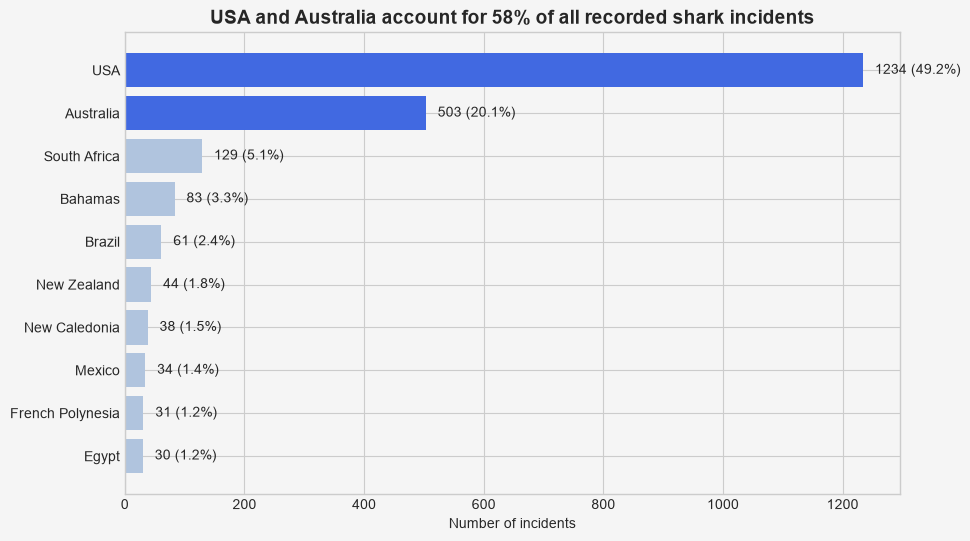

In [41]:
top10 = country_summary.head(10).sort_values("incidents")

#Highlight USA and Australia
colors = []
for country in top10["country"]:
    if country in ["USA", "Australia"]:
        colors.append("royalblue")
    else:
        colors.append("lightsteelblue")

plt.figure(figsize=(10, 6))
plt.barh(top10["country"], top10["incidents"], color=colors)

#Add incidents and % next to each bar
for i, (value, pct) in enumerate(zip(top10["incidents"], top10["percentage"])):
    plt.text(value + 20, i, f"{value} ({pct}%)", va="center")

plt.title("USA and Australia account for 58% of all recorded shark incidents", fontsize=14, fontweight="bold")
plt.xlabel("Number of incidents")
plt.savefig("top_countries.png", dpi=200, bbox_inches="tight")
plt.show()

In [42]:
# top10 = country_summary.head(10).sort_values("incidents")

# #Highlight USA and Australia
# colors = []
# for country in top10["country"]:
#     if country in ["USA", "Australia"]:
#         colors.append("royalblue")
#     else:
#         colors.append("lightsteelblue")

# plt.figure(figsize=(10, 6))
# plt.barh(top10["country"], top10["incidents"], color=colors)

# #Add the number of incidents next to each bar
# for i, value in enumerate(top10["incidents"]):
#     plt.text(value + 20, i, value, va="center")

# plt.title("USA and Australia have the most shark incidents", fontsize=14, fontweight="bold")
# plt.xlabel("Number of incidents")
# plt.savefig("top_countries.png", dpi=200, bbox_inches="tight")
# plt.show()

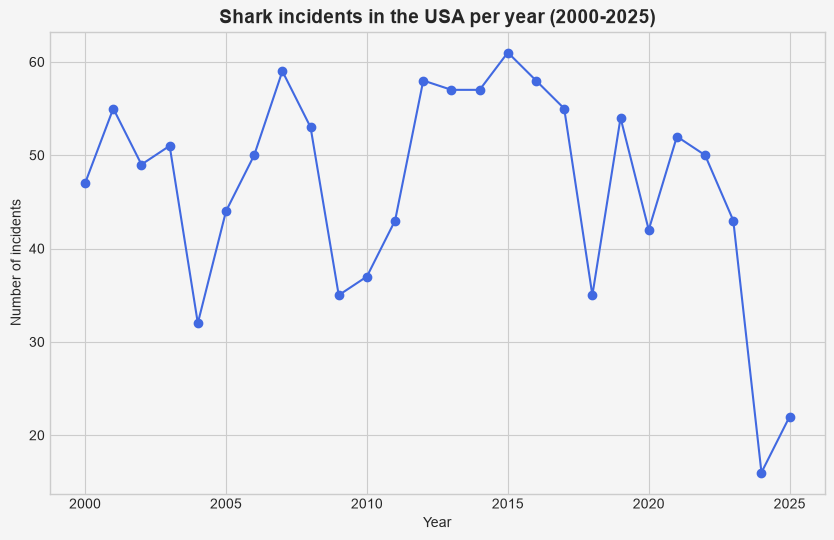

In [43]:
usa_years = country_years[country_years["year"].between(2000, 2025)]

plt.figure(figsize=(10, 6))
plt.plot(usa_years["year"], usa_years["incidents"], color="royalblue", marker="o")

plt.title("Shark incidents in the USA per year (2000-2025)", fontsize=14, fontweight="bold")
plt.xlabel("Year")
plt.ylabel("Number of incidents")
plt.savefig("usa_years.png", dpi=200, bbox_inches="tight")
plt.show()

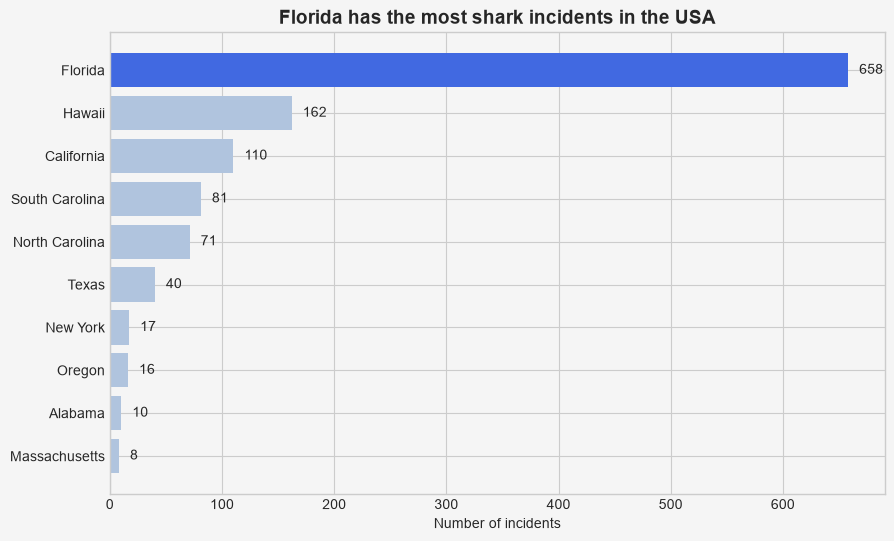

In [44]:
top_states = state_summary.head(10).sort_values("incidents")

#Highlight Florida
colors = []
for state in top_states["state"]:
    if state == "Florida":
        colors.append("royalblue")
    else:
        colors.append("lightsteelblue")

plt.figure(figsize=(10, 6), facecolor="whitesmoke")
plt.gca().set_facecolor("whitesmoke")
plt.barh(top_states["state"], top_states["incidents"], color=colors)

#Add the number of incidents next to each bar
for i, value in enumerate(top_states["incidents"]):
    plt.text(value + 10, i, value, va="center")

plt.title("Florida has the most shark incidents in the USA", fontsize=14, fontweight="bold")
plt.xlabel("Number of incidents")
plt.savefig("top_states.png", dpi=200, bbox_inches="tight", facecolor="whitesmoke")
plt.show()

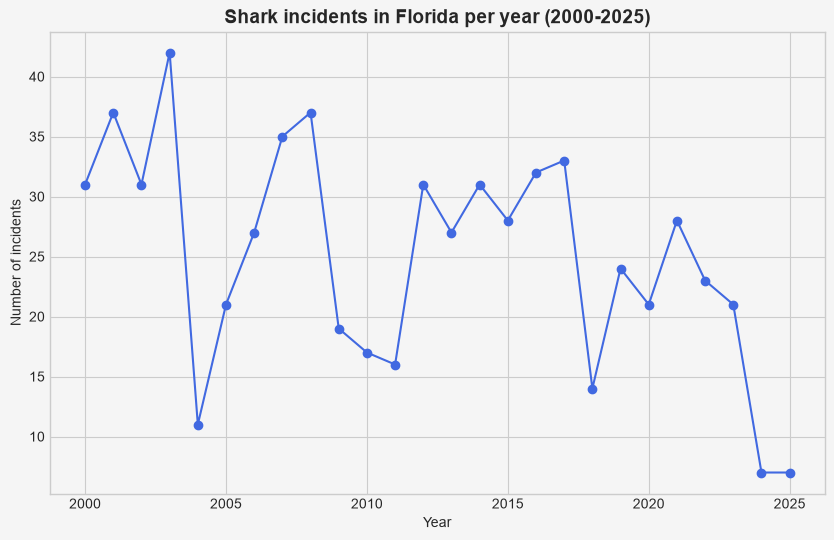

In [45]:
florida_years = state_years[state_years["year"].between(2000, 2025)]

plt.figure(figsize=(10, 6), facecolor="whitesmoke")
plt.gca().set_facecolor("whitesmoke")
plt.plot(florida_years["year"], florida_years["incidents"], color="royalblue", marker="o")

plt.title("Shark incidents in Florida per year (2000-2025)", fontsize=14, fontweight="bold")
plt.xlabel("Year")
plt.ylabel("Number of incidents")
plt.savefig("florida_years.png", dpi=200, bbox_inches="tight", facecolor="whitesmoke")
plt.show()

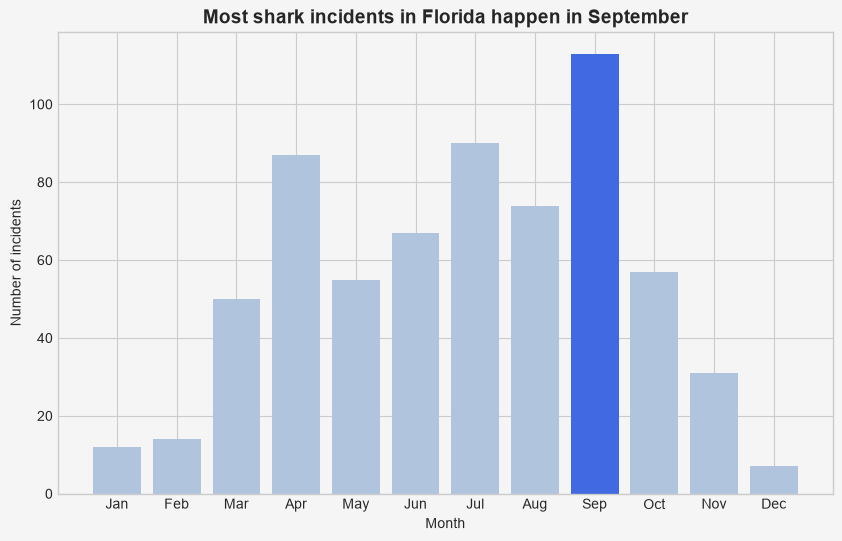

In [46]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

#Highlight the month with the most incidents
colors = []
for value in state_months["incidents"]:
    if value == state_months["incidents"].max():
        colors.append("royalblue")
    else:
        colors.append("lightsteelblue")

plt.figure(figsize=(10, 6), facecolor="whitesmoke")
plt.gca().set_facecolor("whitesmoke")
plt.bar(state_months["month"], state_months["incidents"], color=colors)

#Show month names instead of numbers
plt.xticks(range(1, 13), month_names)
plt.title("Most shark incidents in Florida happen in September", fontsize=14, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Number of incidents")
plt.savefig("florida_months.png", dpi=200, bbox_inches="tight", facecolor="whitesmoke")
plt.show()

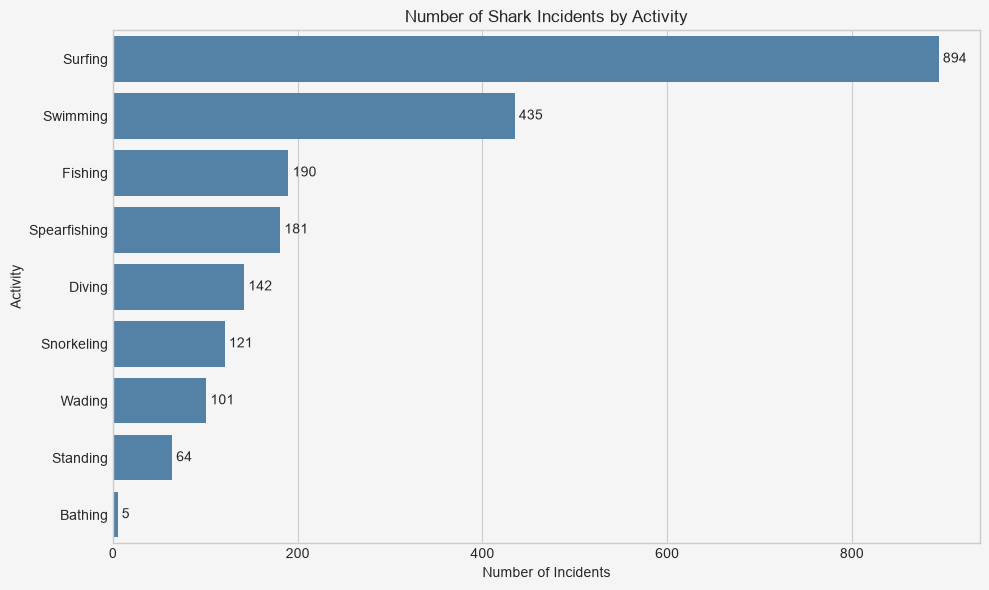

In [47]:
#### H2 - Activity ####

#Count incidents for each activity
activity_counts = (
    df_clean["activity_clean"]
    .value_counts()
    .drop(["Other", "Unknown"], errors="ignore")
    .reset_index()
)

#Give the columns clear names
activity_counts.columns = ["activity", "number_of_incidents"]

#Create the chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=activity_counts,
    x="number_of_incidents",
    y="activity",
    color="steelblue"
)

#Add the numbers to the bars
for container in ax.containers:
    ax.bar_label(container, padding=3)

#Add labels
plt.title("Number of Shark Incidents by Activity")
plt.xlabel("Number of Incidents")
plt.ylabel("Activity")

plt.tight_layout()
plt.savefig("activity_counts.png", dpi=200, bbox_inches="tight")
plt.show()

In [48]:
#### H3 - Incident type ####

# Keep only Provoked and Unprovoked incidents
df_h3 = df_clean[
    df_clean["type_clean"].isin(["Provoked", "Unprovoked"])
]

# Count incidents by type
type_counts = df_h3["type_clean"].value_counts().reset_index()
type_counts.columns = ["type", "incidents"]

# Calculate percentages
type_counts["percentage"] = (
    type_counts["incidents"] / type_counts["incidents"].sum() * 100
).round(1)

display(type_counts)

# Check if Unprovoked incidents are the majority
unprovoked_percentage = type_counts.loc[
    type_counts["type"] == "Unprovoked", "percentage"
].iloc[0]

if unprovoked_percentage > 50:
    print("H3 supported: Most incidents are unprovoked.")
else:
    print("H3 not supported: Unprovoked incidents are not the majority.")


#Hypothesis supported. Between 2000 and 2026, 90.7% of recorded incidents were unprovoked (2,274 incidents), compared to 9.3% provoked (232 incidents).
#This highlights the importance of preventive beach safety measures.

,type,incidents,percentage
0,Unprovoked,2274,90.7
1,Provoked,232,9.3


H3 supported: Most incidents are unprovoked.


In [49]:
#### H4 - Fatality ####

# Keep only incidents with known outcomes
df_h4 = df_clean[
    df_clean["fatal_clean"].isin(["Y", "N"])
]

# Count fatal and non-fatal incidents
fatal_counts = df_h4["fatal_clean"].value_counts().reset_index()
fatal_counts.columns = ["fatal", "incidents"]

# Calculate percentages
fatal_counts["percentage"] = (
    fatal_counts["incidents"] / fatal_counts["incidents"].sum() * 100
).round(1)

display(fatal_counts)

# Check if non-fatal incidents are the majority
non_fatal_percentage = fatal_counts.loc[
    fatal_counts["fatal"] == "N", "percentage"
].iloc[0]

if non_fatal_percentage > 50:
    print("H4 supported: Most incidents are non-fatal.")
else:
    print("H4 not supported: Non-fatal incidents are not the majority.")

#Hypothesis supported. Of the incidents with known outcomes, 89.8% were non-fatal (2,230 incidents), while 10.2% were fatal (253 incidents).
#This shows that the majority of recorded shark incidents did not result in death.

,fatal,incidents,percentage
0,N,2231,89.8
1,Y,253,10.2


H4 supported: Most incidents are non-fatal.


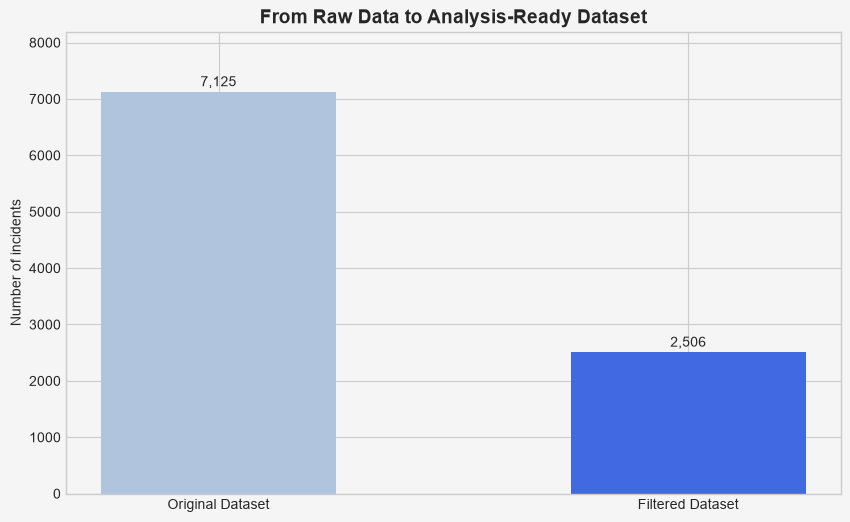

In [50]:
stages = ["Original Dataset", "Filtered Dataset"]
counts = [len(df), len(df_clean)]

colors = ["lightsteelblue", "royalblue"]

plt.figure(figsize=(10, 6))
plt.bar(stages, counts, color=colors, width=0.5)

# Add numbers above the bars
for i, value in enumerate(counts):
    plt.text(i, value + 100, f"{value:,}", ha="center")

plt.title("From Raw Data to Analysis-Ready Dataset",
          fontsize=14, fontweight="bold")
plt.ylabel("Number of incidents")
plt.ylim(0, max(counts) * 1.15)

plt.savefig("dataset_cleaning.png", dpi=200, bbox_inches="tight")
plt.show()

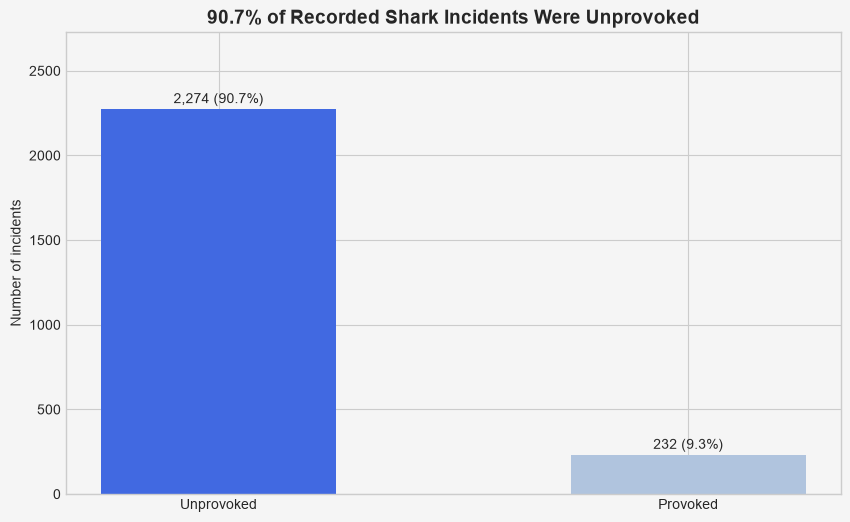

In [51]:
type_chart = type_counts.sort_values("incidents", ascending=False)

colors = []
for incident_type in type_chart["type"]:
    if incident_type == "Unprovoked":
        colors.append("royalblue")
    else:
        colors.append("lightsteelblue")

plt.figure(figsize=(10, 6))
plt.bar(type_chart["type"], type_chart["incidents"], color=colors, width=0.5)

# Add incidents and percentages above bars
for i, (value, pct) in enumerate(zip(type_chart["incidents"], type_chart["percentage"])):
    plt.text(i, value + 35, f"{value:,} ({pct:.1f}%)", ha="center")

plt.title("90.7% of Recorded Shark Incidents Were Unprovoked",
          fontsize=14, fontweight="bold")
plt.ylabel("Number of incidents")
plt.ylim(0, type_chart["incidents"].max() * 1.20)

plt.savefig("incident_types.png", dpi=200, bbox_inches="tight")
plt.show()

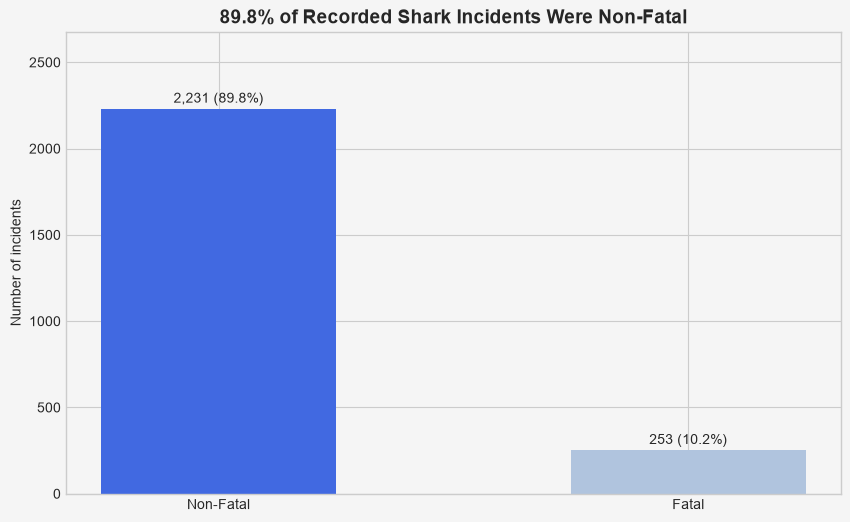

In [52]:
fatal_chart = fatal_counts.sort_values("incidents", ascending=False)

colors = []
for outcome in fatal_chart["fatal"]:
    if outcome == "N":
        colors.append("royalblue")
    else:
        colors.append("lightsteelblue")

# Change labels to readable names
labels = []
for outcome in fatal_chart["fatal"]:
    if outcome == "N":
        labels.append("Non-Fatal")
    else:
        labels.append("Fatal")

plt.figure(figsize=(10, 6))
plt.bar(labels, fatal_chart["incidents"], color=colors, width=0.5)

# Add incidents and percentages above bars
for i, (value, pct) in enumerate(zip(fatal_chart["incidents"], fatal_chart["percentage"])):
    plt.text(i, value + 35, f"{value:,} ({pct:.1f}%)", ha="center")

plt.title("89.8% of Recorded Shark Incidents Were Non-Fatal",
          fontsize=14, fontweight="bold")
plt.ylabel("Number of incidents")
plt.ylim(0, fatal_chart["incidents"].max() * 1.20)

plt.savefig("fatality.png", dpi=200, bbox_inches="tight")
plt.show()